# Install required dependencies

In [1]:
# Install required libraries
%pip install tensorflow numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import TensorFlow
import tensorflow as tf

# Import Keras from TensorFlow
from tensorflow import keras

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for plotting graphs
import matplotlib.pyplot as plt


# Load MNIST training and testing data

In [3]:
# Load MNIST dataset from Keras
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Display training data shape
print("Training Images Shape:", x_train.shape)

# Display training labels shape
print("Training Labels Shape:", y_train.shape)

# Display testing data shape
print("Testing Images Shape:", x_test.shape)

# Display testing labels shape
print("Testing Labels Shape:", y_test.shape)

# Display total training samples
print("Total Training Images:", len(x_train))

# Display total testing samples
print("Total Testing Images:", len(x_test))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 14s 1us/step
Training Images Shape: (60000, 28, 28)
Training Labels Shape: (60000,)
Testing Images Shape: (10000, 28, 28)
Testing Labels Shape: (10000,)
Total Training Images: 60000
Total Testing Images: 10000


# Display sample images

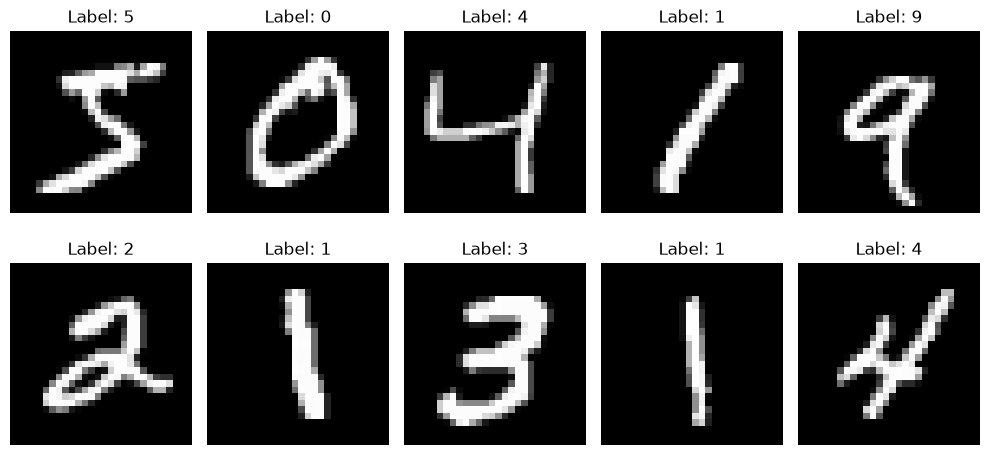

In [5]:
# Create a figure with multiple images
plt.figure(figsize=(10, 5))

# Display first 10 training images
for i in range(10):

    # Create subplot
    plt.subplot(2, 5, i + 1)

    # Display grayscale image
    plt.imshow(x_train[i], cmap='gray')

    # Display actual digit label
    plt.title("Label: " + str(y_train[i]))

    # Hide axis
    plt.axis('off')

# Adjust spacing
plt.tight_layout()

# Display images
plt.show()

# Preprocess the dataset

In [6]:
# Convert pixel values from 0-255 into 0-1
x_train = x_train.astype('float32') / 255.0

# Normalize testing images
x_test = x_test.astype('float32') / 255.0

# Display new training data range
print("Minimum Pixel Value:", x_train.min())

# Display maximum pixel value
print("Maximum Pixel Value:", x_train.max())

# Display processed image shape
print("Processed Training Shape:", x_train.shape)

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Processed Training Shape: (60000, 28, 28)


# Define the Feedforward Neural Network architecture

In [7]:
# Create a sequential neural network
model = keras.Sequential([

    # Flatten 28x28 images into 784 input features
    keras.layers.Flatten(input_shape=(28, 28)),

    # First hidden layer with 128 neurons
    keras.layers.Dense(128, activation='relu'),

    # Second hidden layer with 64 neurons
    keras.layers.Dense(64, activation='relu'),

    # Output layer with 10 neurons for digits 0-9
    keras.layers.Dense(10, activation='softmax')

])

# Display neural network architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

# Compile the model using SGD optimizer

In [8]:
# Compile the neural network
model.compile(

    # Use Stochastic Gradient Descent optimizer
    optimizer=keras.optimizers.SGD(learning_rate=0.01),

    # Use sparse categorical crossentropy loss
    loss='sparse_categorical_crossentropy',

    # Measure model accuracy
    metrics=['accuracy']

)

# Display compilation message
print("Model compiled successfully!")

Model compiled successfully!


# Train the neural network

In [9]:
# Train the neural network
history = model.fit(

    # Training images
    x_train,

    # Training labels
    y_train,

    # Number of complete training cycles
    epochs=10,

    # Number of samples processed per batch
    batch_size=32,

    # Use 10% training data for validation
    validation_split=0.1,

    # Display training progress
    verbose=1

)

# Display training completion message
print("Model training completed!")

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8115 - loss: 0.6984 - val_accuracy: 0.9223 - val_loss: 0.2809
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9120 - loss: 0.3070 - val_accuracy: 0.9385 - val_loss: 0.2191
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9271 - loss: 0.2527 - val_accuracy: 0.9478 - val_loss: 0.1870
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9371 - loss: 0.2178 - val_accuracy: 0.9563 - val_loss: 0.1637
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9447 - loss: 0.1914 - val_accuracy: 0.9610 - val_loss: 0.1459
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9508 - loss: 0.1707 - val_accuracy: 0.9642 - val_loss: 0.1327
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9553 - loss: 0.1542 - val_accuracy: 0.9673 - val_loss: 0.1230
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9594 - loss: 0.1406 

# Evaluate the trained model

In [10]:
# Evaluate the model using testing data
test_loss, test_accuracy = model.evaluate(x_test, y_test)

# Display testing loss
print("Test Loss:", test_loss)

# Display testing accuracy in percentage
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9654 - loss: 0.1181
Test Loss: 0.11809413135051727
Test Accuracy: 96.5399980545044 %


# Plot training and validation accuracy

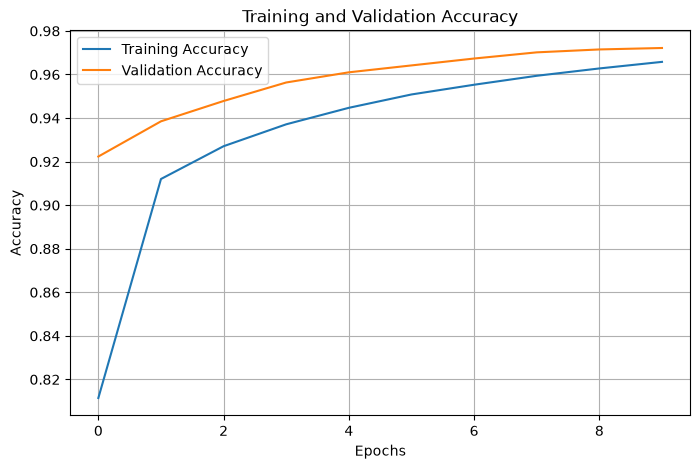

In [11]:
# Create figure for accuracy graph
plt.figure(figsize=(8, 5))

# Plot training accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')

# Plot validation accuracy
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

# Add graph title
plt.title('Training and Validation Accuracy')

# Add X-axis label
plt.xlabel('Epochs')

# Add Y-axis label
plt.ylabel('Accuracy')

# Display legend
plt.legend()

# Display grid
plt.grid(True)

# Show graph
plt.show()

# Plot training and validation loss

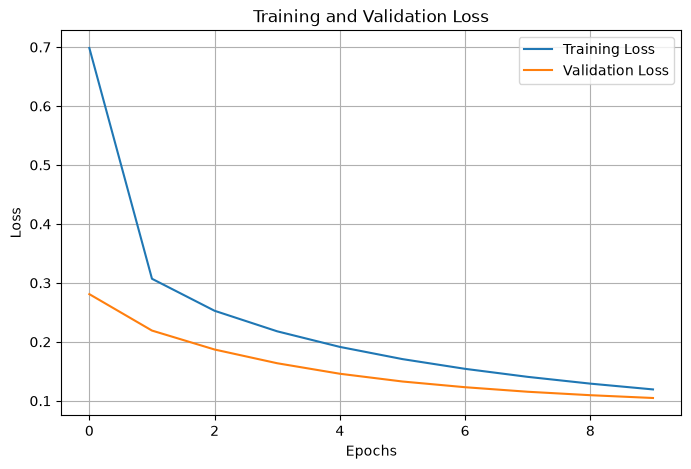

In [12]:
# Create figure for loss graph
plt.figure(figsize=(8, 5))

# Plot training loss
plt.plot(history.history['loss'], label='Training Loss')

# Plot validation loss
plt.plot(history.history['val_loss'], label='Validation Loss')

# Add graph title
plt.title('Training and Validation Loss')

# Add X-axis label
plt.xlabel('Epochs')

# Add Y-axis label
plt.ylabel('Loss')

# Display legend
plt.legend()

# Display grid
plt.grid(True)

# Show graph
plt.show()

# Predict handwritten digits

In [13]:
# Predict the first 10 testing images
predictions = model.predict(x_test[:10])

# Get the class with the highest probability
predicted_labels = np.argmax(predictions, axis=1)

# Display actual and predicted values
for i in range(10):

    print(
        "Actual Digit:", y_test[i],
        "| Predicted Digit:", predicted_labels[i]
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
Actual Digit: 7 | Predicted Digit: 7
Actual Digit: 2 | Predicted Digit: 2
Actual Digit: 1 | Predicted Digit: 1
Actual Digit: 0 | Predicted Digit: 0
Actual Digit: 4 | Predicted Digit: 4
Actual Digit: 1 | Predicted Digit: 1
Actual Digit: 4 | Predicted Digit: 4
Actual Digit: 9 | Predicted Digit: 9
Actual Digit: 5 | Predicted Digit: 6
Actual Digit: 9 | Predicted Digit: 9


# Display predicted images

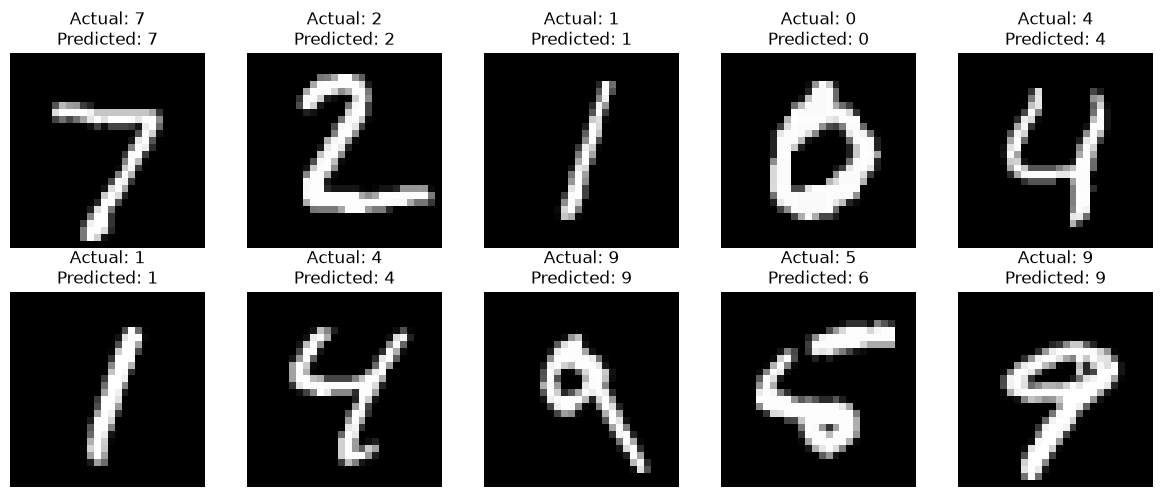

In [14]:
# Create visualization area
plt.figure(figsize=(12, 5))

# Display first 10 testing images
for i in range(10):

    # Create subplot
    plt.subplot(2, 5, i + 1)

    # Display image
    plt.imshow(x_test[i], cmap='gray')

    # Display actual and predicted labels
    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predicted_labels[i]}"
    )

    # Hide axis
    plt.axis('off')

# Adjust layout
plt.tight_layout()

# Display images
plt.show()